WAHHABI Zakaria 23009144 G3 Finance

## 1. Sujet et problématique

- **Intérêt du sujet :** Les journées de krach ou de rebond brutal concentrent l'essentiel des pertes d'un portefeuille. Les repérer automatiquement intéresse les gestionnaires de portefeuille et les risk managers : une journée signalée comme atypique peut déclencher une revue des positions, une réduction de l'exposition ou l'intégration du scénario dans les stress tests. Le sujet prolonge aussi mon cours de bourse, en reliant un outil statistique à des événements de marché réels.

- **Problématique :** Un Isolation Forest entraîné sur les rendements et la volatilité du S&P 500 de 2016 à 2021 permet-il de repérer, sur la période 2022-2026, des journées atypiques qui correspondent à des événements de marché documentés, mieux qu'une simple règle des trois écarts-types ?

- **Objectif mesurable :**
  - *Métrique principale :* précision événementielle, c'est-à-dire la part des anomalies détectées sur la période de test qui tombent dans une fenêtre d'événement documenté et sourcé.
  - *Référence naïve :* règle des trois écarts-types (rendement à plus de 3 écarts-types de la moyenne, calculés sur l'apprentissage).
  - *Période de test :* du 1er janvier 2022 à la date d'extraction des données.
  - *Seuil de réussite (fixé avant les résultats) :* la précision événementielle de l'Isolation Forest est au moins **deux fois supérieure au niveau du hasard** (part de tous les jours du test situés dans une fenêtre d'événement) **et au moins égale** à celle de la référence.
  - La liste des événements et leurs fenêtres sont fixées et sourcées **avant** d'appliquer le modèle au test.

- **Nature du problème :** Détection d'anomalies, en apprentissage non supervisé. Il n'existe aucune variable cible : aucune journée n'est étiquetée « normale » ou « anormale » dans les données. Une classification est donc impossible ; le modèle doit identifier seul les observations qui s'écartent de la majorité. L'évaluation se fait a posteriori, par confrontation à des événements documentés.

- **Algorithme principal envisagé :** n° 24, Isolation Forest.

**Configuration**

In [30]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

GRAINE = 42
np.random.seed(GRAINE)

In [31]:
from google.colab import drive
drive.mount('/content/drive')
FICHIER = Path("/content/drive/MyDrive/SP500 (1).csv")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

print("Fichier trouvé :", FICHIER.exists())
print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__, "| numpy :", np.__version__,
      "| scikit-learn :", sklearn.__version__, "| matplotlib :", matplotlib.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fichier trouvé : True
Python : 3.13.18
pandas : 2.2.3 | numpy : 2.4.6 | scikit-learn : 1.6.1 | matplotlib : 3.10.0


**Jeux de donnée**:

## 2. Jeu de données

- **Nom et source :** S&P 500 (série SP500), S&P Dow Jones Indices LLC, diffusé par FRED (Federal Reserve Bank of St. Louis).
- **Lien :** https://fred.stlouisfed.org/series/SP500
- **Date d'extraction :** ...
- **Licence :** la reproduction de la série est interdite sans autorisation écrite de S&P Dow Jones Indices. Les données ne sont donc pas redistribuées dans le dépôt public : `data/raw/LISEZMOI.md` explique comment les obtenir.
-
- **Date d'extraction :** 17/11/2026
- **Taille :** 2 609 observations, 2 variables, du 7 novembre 2016 au 5 novembre 2026, fréquence quotidienne (clôture).
- **Manquants :** 96 valeurs (3,7 %), correspondant aux jours fériés.
- Données chargées depuis Google Drive, méthode validée par l'enseignant le 17/11/2026.

**Dictionnaire des variables**

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| `date` | Jour de cotation | date | jour | index | 0 |
| `cloture` | Valeur de l'indice à la clôture | numérique | points d'indice | brute | ... |
| `rendement` | $r_t = \ln(P_t / P_{t-1})$ | numérique | % | explicative (créée) | — |
| `volatilite_20j` | $\sigma_t = \text{écart-type}(r_{t-20}, \dots, r_{t-1})$ | numérique | % | explicative (créée) | — |

- **Adéquation :** la série permet de mesurer l'ampleur de chaque mouvement et son contexte (agitation récente), ce que la détection d'anomalies doit comparer.
- **Limites :** seulement 10 ans d'historique (pas de crise de 2008) ; indice de prix sans dividendes ; jours fériés codés comme manquants ; aucune étiquette d'anomalie ; liste d'événements choisie par l'auteur.

In [32]:
df = pd.read_csv(FICHIER)
df.columns = ["date", "cloture"]
df["date"] = pd.to_datetime(df["date"])
df["cloture"] = pd.to_numeric(df["cloture"], errors="coerce")  # "." -> valeur manquante

print("Dimensions :", df.shape)
print("Période :", df["date"].min().date(), "→", df["date"].max().date())
print("Valeurs manquantes :", df["cloture"].isna().sum(), f"({100 * df['cloture'].isna().mean():.1f} %)")
print("Doublons de dates :", df["date"].duplicated().sum())
print(df.dtypes)
df.head()

Dimensions : (2609, 2)
Période : 2016-11-07 → 2026-11-05
Valeurs manquantes : 96 (3.7 %)
Doublons de dates : 0
date       datetime64[ns]
cloture           float64
dtype: object


,date,cloture
0,2016-11-07,2131.52
1,2016-11-08,2139.56
2,2016-11-09,2163.26
3,2016-11-10,2167.48
4,2016-11-11,2164.45


## 3. Exploration

### 3.1 Qualité des données

- **Valeurs manquantes :** détectées avec `isna()`. Ce sont les jours fériés (pas de cotation). Décision : suppression, car aucun prix n'existe ces jours-là.
- **Doublons :** vérifiés sur la date.
- **Valeurs atypiques :** les rendements extrêmes sont **conservés**. En finance, ils correspondent à de vrais krachs : ce sont justement eux qu'on cherche.

In [33]:
if "date" in df.columns:   # évite une erreur si la cellule est relancée
    lignes_avant = len(df)
    df = df.dropna(subset=["cloture"]).set_index("date").sort_index()
    print(f"Lignes avant : {lignes_avant} | après : {len(df)} | supprimées : {lignes_avant - len(df)}")
df["cloture"].describe().round(1)

Lignes avant : 2609 | après : 2513 | supprimées : 96


,cloture
count,2513.0
mean,4214.0
std,1515.4
min,2131.5
25%,2867.2
50%,3999.1
75%,5209.9
max,7818.9


 **Lecture.** 96 jours sans cotation ont été supprimés ; il reste 2 513 jours de bourse. L'indice passe de 2 131,5 à 7 818,9 points. Aucun doublon de date.

### 3.2 Évolution de l'indice

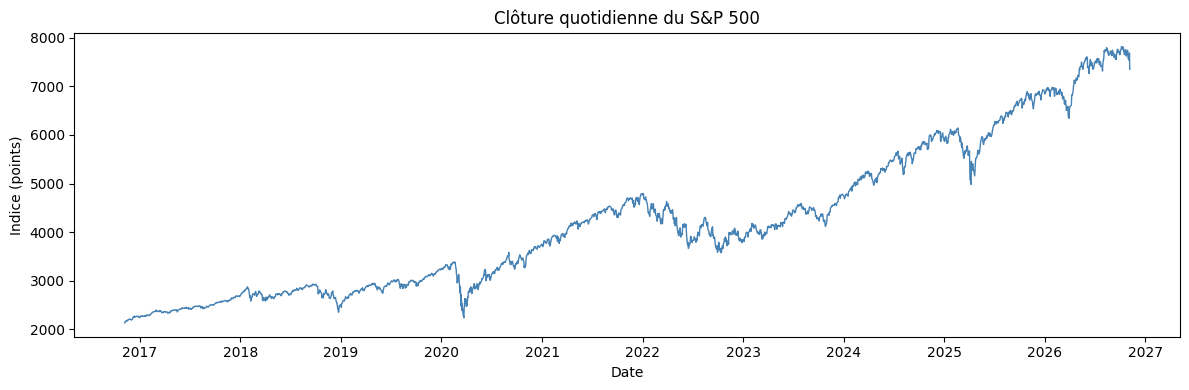

In [34]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["cloture"], color="steelblue", lw=1)
ax.set_title("Clôture quotidienne du S&P 500")
ax.set_xlabel("Date")
ax.set_ylabel("Indice (points)")
plt.tight_layout()
plt.savefig(FIGURES / "fig1_cours.png", dpi=150)
plt.show()

**Lecture.** L'indice monte sur la période, avec des chutes brutales (notamment début 2020). Le niveau du prix n'est donc pas utilisable directement : une valeur élevée traduit la croissance, pas une anomalie. Il faut travailler sur les variations.

### 3.3 Rendements quotidiens dans le temps

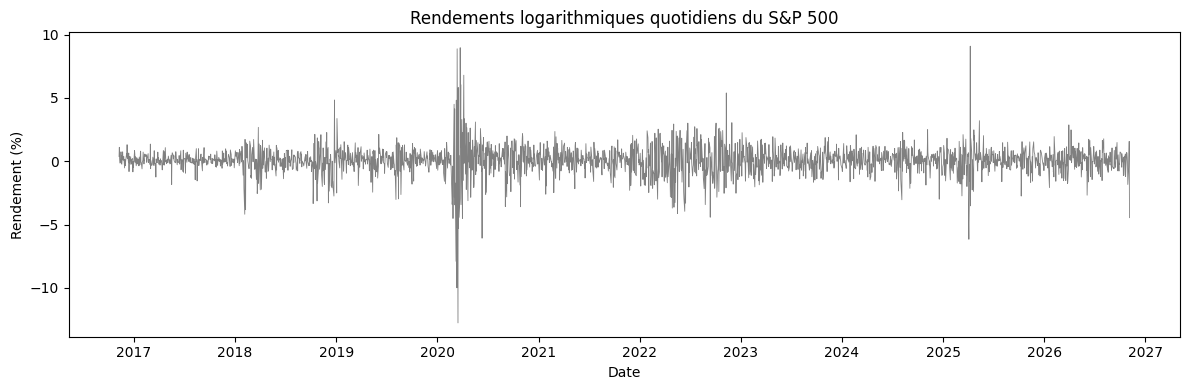

In [35]:
rendement_pct = 100 * np.log(df["cloture"]).diff()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(rendement_pct.index, rendement_pct, color="grey", lw=0.6)
ax.set_title("Rendements logarithmiques quotidiens du S&P 500")
ax.set_xlabel("Date")
ax.set_ylabel("Rendement (%)")
plt.tight_layout()
plt.savefig(FIGURES / "fig2_rendements.png", dpi=150)
plt.show()

**Lecture.** Le kurtosis en excès vaut 16,6 (0 pour une loi normale). 37 jours sur 2 512, soit 1,47 %, dépassent 3 écarts-types, contre 0,27 % attendu : environ 5 fois plus que prévu. Ce sont les queues épaisses, qui justifient la détection d'anomalies.

### 3.4 Distribution des rendements

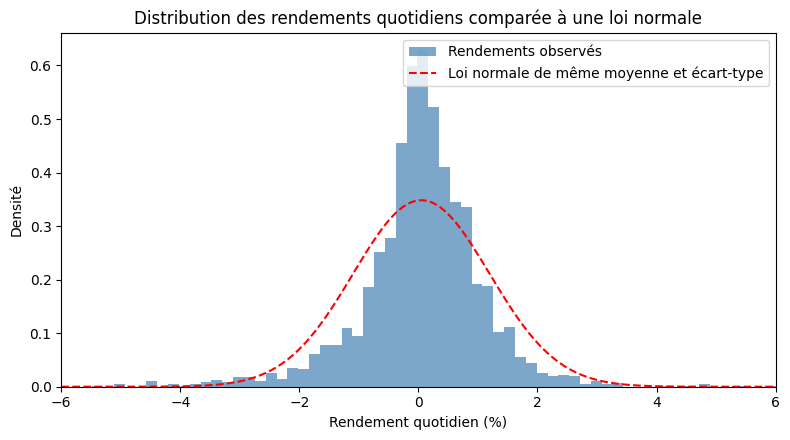

Kurtosis en excès : 16.6 (0 pour une loi normale)
Jours à plus de 3 écarts-types : 37 sur 2512 (1.47 %), contre environ 0,27 % attendu pour une loi normale


In [36]:
r = rendement_pct.dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(r, bins=120, density=True, color="steelblue", alpha=0.7, label="Rendements observés")
x = np.linspace(-6, 6, 400)
ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r--", label="Loi normale de même moyenne et écart-type")
ax.set_xlim(-6, 6)
ax.set_title("Distribution des rendements quotidiens comparée à une loi normale")
ax.set_xlabel("Rendement quotidien (%)")
ax.set_ylabel("Densité")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fig3_distribution.png", dpi=150)
plt.show()

z = (r - r.mean()) / r.std()
print(f"Kurtosis en excès : {stats.kurtosis(r):.1f} (0 pour une loi normale)")
print(f"Jours à plus de 3 écarts-types : {(z.abs() > 3).sum()} sur {len(r)} "
      f"({100 * (z.abs() > 3).mean():.2f} %), contre environ 0,27 % attendu pour une loi normale")

**Lecture.** À compléter avec le kurtosis et le pourcentage obtenus. Les valeurs extrêmes sont bien plus fréquentes qu'avec une loi normale : ce sont les **queues épaisses**. Les journées extrêmes existent et se répètent, ce qui justifie de les détecter.

## 4. Préparation

**Variables créées** (formules dans le dictionnaire) :
- `rendement` : mouvement du jour, comparable d'une année à l'autre.
- `volatilite_20j` : écart-type des 20 rendements **précédents** (`shift(1)`). Elle décrit la situation **avant** le jour étudié et n'utilise que le passé.

**Prévention des fuites :**
- Découpage **chronologique** sans mélange : apprentissage avant 2022, test à partir de 2022.
- Le réglage du taux d'anomalies se fait dans l'apprentissage : sous-période 2016-2019 pour ajuster, 2020-2021 pour valider.
- La standardisation est placée dans un **Pipeline** : elle est ajustée sur l'apprentissage seulement, puis appliquée au test.
- Le test n'est utilisé **qu'une seule fois**, à la fin.

**Mise à l'échelle :** nécessaire, car les deux variables n'ont pas la même échelle ; sans elle, l'une dominerait les coupes de l'Isolation Forest.

In [37]:
df["rendement"] = np.log(df["cloture"]).diff()
df["volatilite_20j"] = df["rendement"].rolling(20).std().shift(1)
donnees = df.dropna(subset=["rendement", "volatilite_20j"]).copy()
VARIABLES = ["rendement", "volatilite_20j"]
print("Observations utilisables :", len(donnees))

# Preuve de l'alignement : la volatilité d'un jour n'utilise que les 20 jours précédents
t = donnees.index[5]
pos = df.index.get_loc(t)
verif = df["rendement"].iloc[pos - 20:pos].std()
print(f"Vérification au {t.date()} : calcul à la main = {verif:.6f} | tableau = "
      f"{donnees.loc[t, 'volatilite_20j']:.6f} | identiques : {np.isclose(verif, donnees.loc[t, 'volatilite_20j'])}")
donnees[["cloture", "rendement", "volatilite_20j"]].head()

Observations utilisables : 2492
Vérification au 2016-12-14 : calcul à la main = 0.004547 | tableau = 0.004547 | identiques : True


,cloture,rendement,volatilite_20j
date,,,
2016-12-07,2241.35,0.013077,0.004155
2016-12-08,2246.19,0.002157,0.004845
2016-12-09,2259.53,0.005921,0.004392
2016-12-12,2256.96,-0.001138,0.004484
2016-12-13,2271.72,0.006518,0.004474


In [39]:
# Découpage chronologique
DEBUT_VALID = "2020-01-01"
DEBUT_TEST = "2022-01-01"
train = donnees[donnees.index < DEBUT_TEST]
test = donnees[donnees.index >= DEBUT_TEST].copy()
train_int = train[train.index < DEBUT_VALID]      # pour régler le taux
valid = train[train.index >= DEBUT_VALID]          # pour valider le réglage

for nom, bloc in [("Apprentissage interne", train_int), ("Validation", valid),
                  ("Apprentissage complet", train), ("Test", test)]:
    print(f"{nom:22s} : {bloc.index.min().date()} → {bloc.index.max().date()} ({len(bloc)} jours)")

# Pipeline : standardisation + Isolation Forest
def creer_modele(taux, graine=GRAINE):
    return Pipeline([
        ("standardisation", StandardScaler()),
        ("iforest", IsolationForest(n_estimators=300, contamination=taux, random_state=graine)),
    ])

Apprentissage interne  : 2016-12-07 → 2019-12-31 (771 jours)
Validation             : 2020-01-02 → 2021-12-31 (505 jours)
Apprentissage complet  : 2016-12-07 → 2021-12-31 (1276 jours)
Test                   : 2022-01-03 → 2026-11-05 (1216 jours)


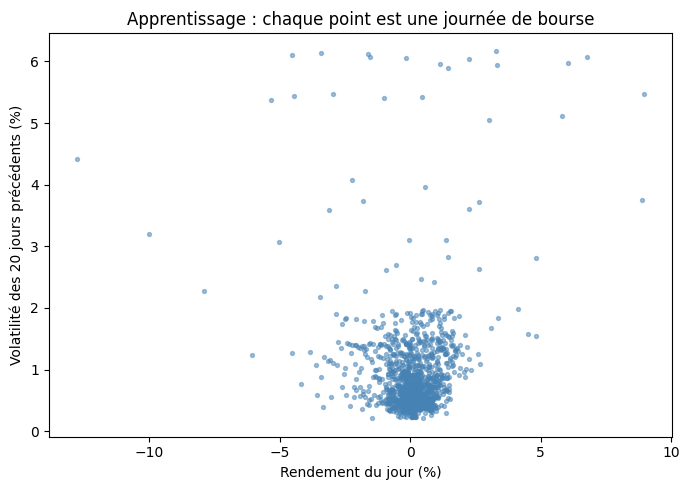

In [40]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train["rendement"] * 100, train["volatilite_20j"] * 100, s=8, alpha=0.5, color="steelblue")
ax.set_title("Apprentissage : chaque point est une journée de bourse")
ax.set_xlabel("Rendement du jour (%)")
ax.set_ylabel("Volatilité des 20 jours précédents (%)")
plt.tight_layout()
plt.savefig(FIGURES / "fig4_nuage.png", dpi=150)
plt.show()

**Lecture.** La plupart des journées forment un nuage dense (rendement proche de zéro, faible volatilité). Les points isolés sur les bords sont les candidats anomalies.

## 5. Algorithme : Isolation Forest (n° 24)

**Principe.** Une anomalie est rare et différente, donc **facile à isoler**. Le modèle construit des arbres qui coupent l'espace au hasard (une variable au hasard, un seuil au hasard). Un point normal, entouré de voisins, demande beaucoup de coupes ; un point atypique est isolé en très peu de coupes. On fait la moyenne sur de nombreux arbres.

**Score d'anomalie :**
$$s(x, n) = 2^{-\frac{E[h(x)]}{c(n)}}$$
- $x$ : une journée (rendement, volatilité) ;
- $h(x)$ : nombre de coupes nécessaires pour isoler $x$ dans un arbre ;
- $E[h(x)]$ : moyenne de $h(x)$ sur tous les arbres ;
- $n$ : nombre d'observations utilisées par arbre ;
- $c(n) = 2H(n-1) - \frac{2(n-1)}{n}$ : longueur moyenne d'isolement, qui sert à normaliser ; $H(i) \approx \ln(i) + 0{,}5772$.

Plus $s$ est proche de 1, plus le point est atypique.

**Paramètres appris :** les coupes de chaque arbre et le seuil de décision. **Hyperparamètres fixés :**
- `contamination` : part des jours d'apprentissage classés anormaux ; il fixe le seuil. Plus il est élevé, plus on détecte de jours, mais des jours moins extrêmes.
- `n_estimators` (300) : nombre d'arbres ; davantage d'arbres donne un score plus stable.
- `max_samples` (par défaut) : nombre d'observations par arbre.

**Pourquoi ce choix :** c'est le seul algorithme du support conçu pour la détection d'anomalies ; il fonctionne sans étiquettes et attribue un score à chaque jour. **DBSCAN** (n° 19) a été écarté : il dépend d'un rayon difficile à régler et ne peut pas noter de nouvelles journées (pas de `predict`).

## 6. Protocole expérimental

- **Découpage :** apprentissage 2016-2021 (avec 2016-2019 pour ajuster et 2020-2021 pour valider), test de 2022 à la fin des données.
- **Référence naïve :** un jour est anormal si son rendement s'écarte de plus de **3 écarts-types** de la moyenne (calculés sur l'apprentissage).
- **Métrique principale :** **précision événementielle** (%) = part des anomalies détectées situées dans une fenêtre d'événement documenté.
- **Niveau du hasard :** part de tous les jours de la période situés dans une fenêtre d'événement. Un modèle utile doit faire nettement mieux.
- **Métriques secondaires :** proportion de jours détectés (%) ; **rappel événementiel** (%) = part des événements de la période contenant au moins une anomalie.
- **Réglage :** `contamination` parmi 0,5 %, 1 %, 2 % et 5 % (4 configurations), choisi sur la validation.
- **Incertitude :** stabilité selon 5 graines aléatoires.

Les événements ci-dessous sont fixés **avant** l'évaluation du test, et sourcés dans la section 10.

In [41]:
EVENEMENTS = {
    "Volmageddon": ("2018-02-01", "2018-02-12"),
    "Correction d'octobre 2018": ("2018-10-01", "2018-10-31"),
    "Chute de décembre 2018": ("2018-12-01", "2018-12-31"),
    "Guerre commerciale, août 2019": ("2019-08-01", "2019-08-23"),
    "Krach du Covid-19": ("2020-02-20", "2020-04-30"),
    "Rechute de juin 2020": ("2020-06-08", "2020-06-15"),
    "Invasion de l'Ukraine": ("2022-02-24", "2022-03-09"),
    "Inflation et Fed, mai-juin 2022": ("2022-05-01", "2022-06-17"),
    "Inflation (CPI), 13 sept. 2022": ("2022-09-13", "2022-09-16"),
    "Inflation (CPI), 10 nov. 2022": ("2022-11-10", "2022-11-11"),
    "Faillite de SVB": ("2023-03-08", "2023-03-17"),
    "Débouclage du carry trade sur le yen": ("2024-08-01", "2024-08-09"),
    "Droits de douane américains": ("2025-04-02", "2025-04-15"),
}

def etiqueter(index):
    etiquettes = pd.Series("Non identifié", index=index)
    for nom, (debut, fin) in EVENEMENTS.items():
        etiquettes[(index >= debut) & (index <= fin)] = nom
    return etiquettes

def evaluer(detecte, index):
    detecte = np.asarray(detecte)
    etiquettes = etiqueter(index)
    dans_evenement = (etiquettes != "Non identifié").values
    n = int(detecte.sum())
    precision = dans_evenement[detecte].mean() if n > 0 else np.nan
    hasard = dans_evenement.mean()
    evenements_periode = set(etiquettes[dans_evenement])
    trouves = set(etiquettes[detecte & dans_evenement])
    rappel = len(trouves) / len(evenements_periode) if evenements_periode else np.nan
    return {
        "Jours détectés": n,
        "Proportion (%)": round(100 * n / len(index), 2),
        "Précision événementielle (%)": round(100 * precision, 1),
        "Niveau du hasard (%)": round(100 * hasard, 1),
        "Ratio / hasard": round(precision / hasard, 2) if hasard > 0 else np.nan,
        "Rappel événementiel (%)": round(100 * rappel, 1),
    }

def regle_3sigma(apprentissage, a_noter):
    mu, sigma = apprentissage["rendement"].mean(), apprentissage["rendement"].std()
    return ((a_noter["rendement"] - mu).abs() > 3 * sigma).values

,Taux (%),Période,Jours détectés,Proportion (%),Précision événementielle (%),Niveau du hasard (%),Ratio / hasard,Rappel événementiel (%)
0,0.5,Apprentissage,4,0.52,75.0,8.7,8.63,75.0
1,0.5,Validation,31,6.14,96.8,11.1,8.73,100.0
2,1.0,Apprentissage,8,1.04,75.0,8.7,8.63,100.0
3,1.0,Validation,51,10.10,78.4,11.1,7.07,100.0
4,2.0,Apprentissage,16,2.08,56.2,8.7,6.47,100.0
5,2.0,Validation,67,13.27,70.1,11.1,6.33,100.0
6,5.0,Apprentissage,39,5.06,38.5,8.7,4.43,100.0
7,5.0,Validation,87,17.23,56.3,11.1,5.08,100.0


Configurations essayées : 4 | taux retenu : 0.5%


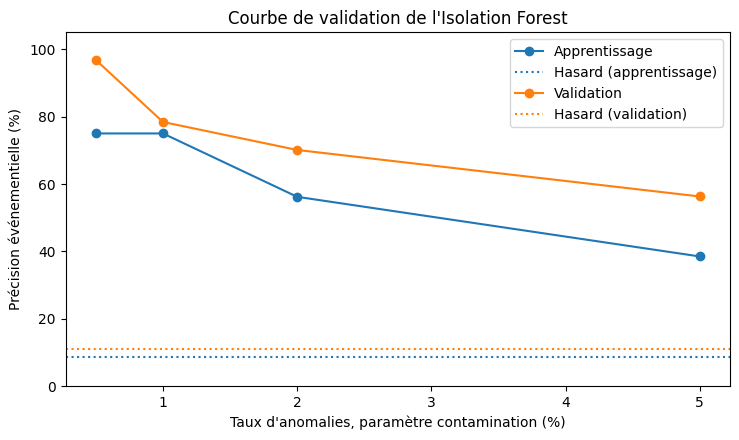

In [42]:
TAUX_CANDIDATS = [0.005, 0.01, 0.02, 0.05]
lignes = []
for taux in TAUX_CANDIDATS:
    m = creer_modele(taux).fit(train_int[VARIABLES])
    for nom, bloc in [("Apprentissage", train_int), ("Validation", valid)]:
        detecte = m.predict(bloc[VARIABLES]) == -1
        lignes.append({"Taux (%)": 100 * taux, "Période": nom, **evaluer(detecte, bloc.index)})
reglage = pd.DataFrame(lignes)
display(reglage)

choix = (reglage[reglage["Période"] == "Validation"]
         .sort_values(["Précision événementielle (%)", "Taux (%)"], ascending=[False, True]).iloc[0])
TAUX = choix["Taux (%)"] / 100
print(f"Configurations essayées : {len(TAUX_CANDIDATS)} | taux retenu : {TAUX:.1%}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for nom, couleur in [("Apprentissage", "tab:blue"), ("Validation", "tab:orange")]:
    sous = reglage[reglage["Période"] == nom]
    ax.plot(sous["Taux (%)"], sous["Précision événementielle (%)"], "o-", color=couleur, label=nom)
    ax.axhline(sous["Niveau du hasard (%)"].iloc[0], color=couleur, ls=":", label=f"Hasard ({nom.lower()})")
ax.set_xlabel("Taux d'anomalies, paramètre contamination (%)")
ax.set_ylabel("Précision événementielle (%)")
ax.set_title("Courbe de validation de l'Isolation Forest")
ax.set_ylim(0, 105)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fig5_courbe_validation.png", dpi=150)
plt.show()

**Lecture.** Sur 4 configurations, le taux retenu est 0,5 %, avec une précision de 96,8 % en validation contre 11,1 % pour le hasard (ratio 8,7). La précision baisse quand le taux augmente, sur les deux courbes. Elle est plus élevée en validation (96,8 %) qu'en apprentissage (75 %) parce que la validation contient le krach du Covid, très facile à détecter : le modèle y signale d'ailleurs 6,1 % des jours, bien plus que les 0,5 % fixés.

In [43]:
ensembles, lignes = {}, []
for g in [0, 1, 2, 3, 42]:
    detecte = creer_modele(TAUX, graine=g).fit(train_int[VARIABLES]).predict(valid[VARIABLES]) == -1
    ensembles[g] = set(valid.index[detecte])
    lignes.append({"Graine": g, **evaluer(detecte, valid.index)})
stab = pd.DataFrame(lignes)
stab["Recouvrement avec la graine 42"] = [
    round(len(ensembles[g] & ensembles[42]) / max(1, len(ensembles[g] | ensembles[42])), 2) for g in stab["Graine"]]
display(stab[["Graine", "Jours détectés", "Précision événementielle (%)", "Recouvrement avec la graine 42"]])
print(f"Précision en validation : moyenne {stab['Précision événementielle (%)'].mean():.1f} % | "
      f"écart-type {stab['Précision événementielle (%)'].std():.1f} points")

,Graine,Jours détectés,Précision événementielle (%),Recouvrement avec la graine 42
0,0,33,90.9,0.94
1,1,30,90.0,0.85
2,2,33,90.9,0.94
3,3,33,90.9,0.94
4,42,31,96.8,1.00


Précision en validation : moyenne 91.9 % | écart-type 2.8 points


**Lecture.** À compléter : moyenne et écart-type. Un écart-type faible et un recouvrement élevé montrent que les anomalies ne dépendent pas du hasard de la construction des arbres.

In [50]:
modele = creer_modele(TAUX).fit(train[VARIABLES])
detecte_train = modele.predict(train[VARIABLES]) == -1

test["score"] = -modele.decision_function(test[VARIABLES])   # plus élevé = plus atypique
test["anomalie"] = modele.predict(test[VARIABLES]) == -1
test["anomalie_3sigma"] = regle_3sigma(train, test)
test["evenement"] = etiqueter(test.index)

m_valid = creer_modele(TAUX).fit(train_int[VARIABLES])
tableau = pd.DataFrame([
    {"Méthode": "Référence (3 écarts-types)", "Période": "Validation", **evaluer(regle_3sigma(train_int, valid), valid.index)},
    {"Méthode": "Isolation Forest", "Période": "Validation", **evaluer(m_valid.predict(valid[VARIABLES]) == -1, valid.index)},
    {"Méthode": "Référence (3 écarts-types)", "Période": "Test", **evaluer(test["anomalie_3sigma"], test.index)},
    {"Méthode": "Isolation Forest", "Période": "Test", **evaluer(test["anomalie"], test.index)},
])
display(tableau)

res_if, res_ref = tableau.iloc[3], tableau.iloc[2]
critere_1 = res_if["Ratio / hasard"] >= 2
critere_2 = res_if["Précision événementielle (%)"] >= res_ref["Précision événementielle (%)"]
print(f"Critère 1 (au moins 2 fois le hasard) : {'atteint' if critere_1 else 'non atteint'} ({res_if['Ratio / hasard']})")
print(f"Critère 2 (au moins égal à la référence) : {'atteint' if critere_2 else 'non atteint'} "
      f"({res_if['Précision événementielle (%)']} % contre {res_ref['Précision événementielle (%)']} %)")
print("OBJECTIF :", "ATTEINT" if (critere_1 and critere_2) else "NON ATTEINT")

,Méthode,Période,Jours détectés,Proportion (%),Précision événementielle (%),Niveau du hasard (%),Ratio / hasard,Rappel événementiel (%)
0,Référence (3 écarts-types),Validation,40,7.92,72.5,11.1,6.54,100.0
1,Isolation Forest,Validation,31,6.14,96.8,11.1,8.73,100.0
2,Référence (3 écarts-types),Test,10,0.82,80.0,6.2,12.97,57.1
3,Isolation Forest,Test,0,0.00,NaN,6.2,NaN,0.0


Critère 1 (au moins 2 fois le hasard) : non atteint (nan)
Critère 2 (au moins égal à la référence) : non atteint (nan % contre 80.0 %)
OBJECTIF : NON ATTEINT


**Lecture.** Sur 5 graines, la précision en validation vaut en moyenne 91,9 %, avec un écart-type de 2,8 points ; le recouvrement avec la graine 42 va de 0,85 à 1,00. Les anomalies dépendent peu du hasard de construction des arbres.

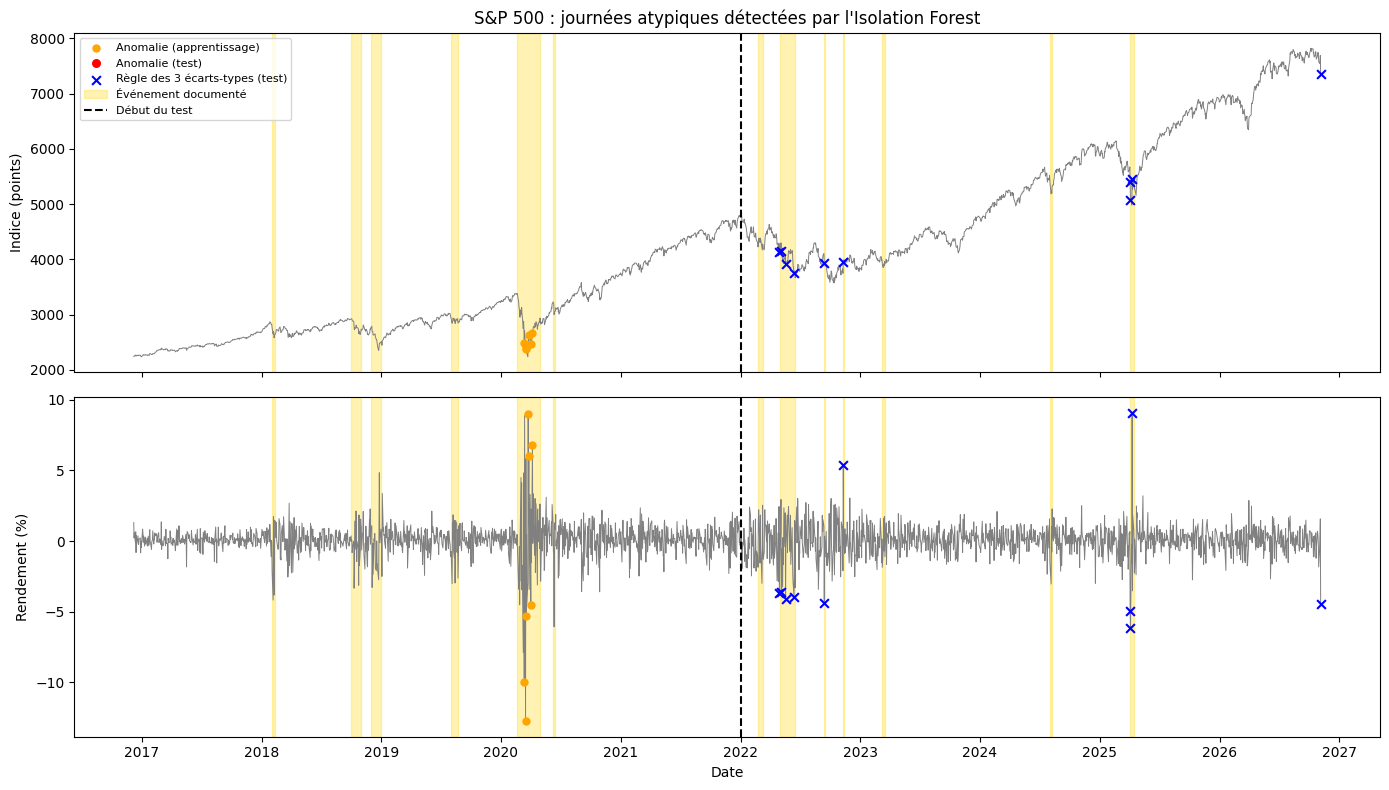

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, col, unite in [(axes[0], "cloture", "Indice (points)"), (axes[1], "rendement", "Rendement (%)")]:
    f = 100 if col == "rendement" else 1
    ax.plot(donnees.index, donnees[col] * f, color="grey", lw=0.7)
    ax.scatter(train.index[detecte_train], train.loc[detecte_train, col] * f, color="orange", s=25, zorder=3, label="Anomalie (apprentissage)")
    ax.scatter(test.index[test["anomalie"]], test.loc[test["anomalie"], col] * f, color="red", s=30, zorder=4, label="Anomalie (test)")
    ax.scatter(test.index[test["anomalie_3sigma"]], test.loc[test["anomalie_3sigma"], col] * f, marker="x", color="blue", s=40, zorder=5, label="Règle des 3 écarts-types (test)")
    for i, (debut, fin) in enumerate(EVENEMENTS.values()):
        ax.axvspan(pd.Timestamp(debut), pd.Timestamp(fin), color="gold", alpha=0.3, label="Événement documenté" if i == 0 else None)
    ax.axvline(pd.Timestamp(DEBUT_TEST), color="black", ls="--", label="Début du test" if ax is axes[0] else None)
    ax.set_ylabel(unite)
axes[0].set_title("S&P 500 : journées atypiques détectées par l'Isolation Forest")
axes[1].set_xlabel("Date")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "fig6_frise.png", dpi=150)
plt.show()

**Lecture.** À compléter : les anomalies tombent-elles dans les bandes jaunes ? Quelles périodes concentrent le plus d'anomalies ?

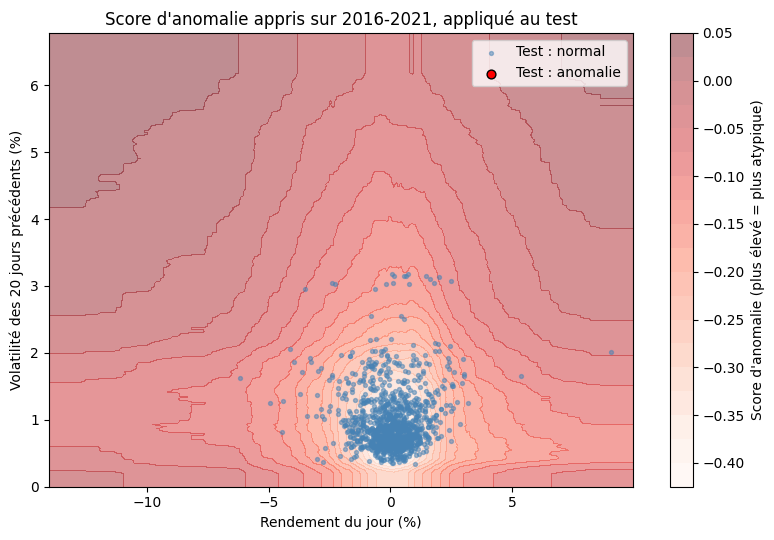

In [46]:
xx, yy = np.meshgrid(np.linspace(donnees["rendement"].min() * 1.1, donnees["rendement"].max() * 1.1, 250),
                     np.linspace(0, donnees["volatilite_20j"].max() * 1.1, 250))
grille = pd.DataFrame({"rendement": xx.ravel(), "volatilite_20j": yy.ravel()})
zz = -modele.decision_function(grille).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 5.5))
fond = ax.contourf(xx * 100, yy * 100, zz, levels=20, cmap="Reds", alpha=0.45)
plt.colorbar(fond, ax=ax, label="Score d'anomalie (plus élevé = plus atypique)")
normal = ~test["anomalie"]
ax.scatter(test.loc[normal, "rendement"] * 100, test.loc[normal, "volatilite_20j"] * 100, s=8, alpha=0.5, color="steelblue", label="Test : normal")
ax.scatter(test.loc[~normal, "rendement"] * 100, test.loc[~normal, "volatilite_20j"] * 100, s=40, color="red", edgecolor="k", label="Test : anomalie")
ax.set_xlabel("Rendement du jour (%)")
ax.set_ylabel("Volatilité des 20 jours précédents (%)")
ax.set_title("Score d'anomalie appris sur 2016-2021, appliqué au test")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fig7_score.png", dpi=150)
plt.show()

**Lecture.** Les zones foncées sont celles que le modèle juge atypiques : forts rendements, surtout quand la volatilité précédente était faible. Une même baisse est donc jugée plus anormale dans un marché calme que dans un marché déjà agité.

In [47]:
par_evenement = []
for nom in [e for e in EVENEMENTS if (test["evenement"] == e).any()]:
    bloc = test[test["evenement"] == nom]
    par_evenement.append({"Événement": nom, "Jours": len(bloc),
                          "Anomalies Isolation Forest": int(bloc["anomalie"].sum()),
                          "Anomalies 3 écarts-types": int(bloc["anomalie_3sigma"].sum()),
                          "Pire rendement (%)": round(100 * bloc["rendement"].min(), 2)})
display(pd.DataFrame(par_evenement))

detail = test.loc[test["anomalie"], ["cloture", "rendement", "volatilite_20j", "score", "anomalie_3sigma", "evenement"]].copy()
detail["rendement"] = (100 * detail["rendement"]).round(2)
detail["volatilite_20j"] = (100 * detail["volatilite_20j"]).round(2)
print("Toutes les anomalies du test :")
display(detail.sort_values("score", ascending=False).round(3))

,Événement,Jours,Anomalies Isolation Forest,Anomalies 3 écarts-types,Pire rendement (%)
0,Invasion de l'Ukraine,10,0,0,-3.00
1,"Inflation et Fed, mai-juin 2022",34,0,3,-4.12
2,"Inflation (CPI), 13 sept. 2022",4,0,1,-4.42
3,"Inflation (CPI), 10 nov. 2022",2,0,1,0.92
4,Faillite de SVB,8,0,0,-1.86
5,Débouclage du carry trade sur le yen,7,0,0,-3.04
6,Droits de douane américains,10,0,3,-6.16


Toutes les anomalies du test :


,cloture,rendement,volatilite_20j,score,anomalie_3sigma,evenement
date,,,,,,


**Lecture.** À compléter :
- **Événements manqués** (0 anomalie) : pourquoi ? Par exemple une baisse étalée sur plusieurs jours, sans journée extrême isolée.
- **Anomalies « Non identifiées »** : chercher l'actualité de ces dates. Soit un événement absent de la liste, soit une fausse alerte.
- Ne pas confondre **atypique** et **erroné** : ces journées sont réelles, elles ne sont pas des erreurs de données.

Proportion signalée : apprentissage 0.55 % | test 0.00 %


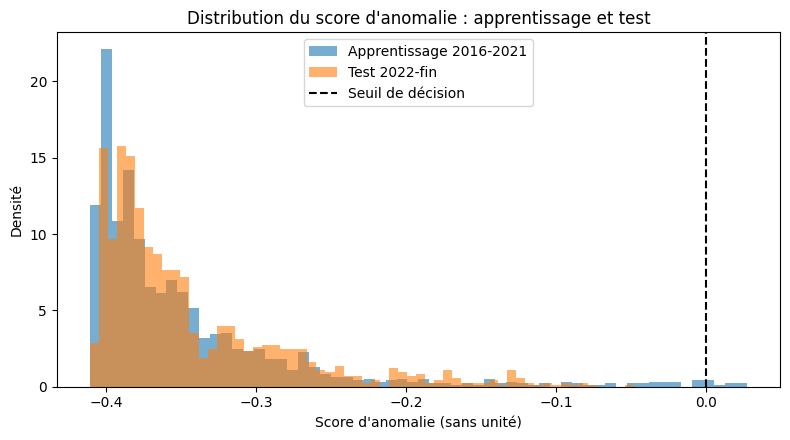

,Sous-période,Jours détectés,Proportion (%),Précision événementielle (%),Niveau du hasard (%),Ratio / hasard,Rappel événementiel (%)
0,Test 2022-2023,0,0.0,NaN,11.6,NaN,0.0
1,Test 2024-fin,0,0.0,NaN,2.4,NaN,0.0


Moyennes en valeur absolue (%) selon le verdict :


,rendement,volatilite_20j
anomalie,,
False,0.77,0.98


In [48]:
print(f"Proportion signalée : apprentissage {100 * detecte_train.mean():.2f} % | test {100 * test['anomalie'].mean():.2f} %")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(-modele.decision_function(train[VARIABLES]), bins=60, density=True, alpha=0.6, label="Apprentissage 2016-2021")
ax.hist(test["score"], bins=60, density=True, alpha=0.6, label="Test 2022-fin")
ax.axvline(0, color="black", ls="--", label="Seuil de décision")
ax.set_xlabel("Score d'anomalie (sans unité)")
ax.set_ylabel("Densité")
ax.set_title("Distribution du score d'anomalie : apprentissage et test")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fig8_scores.png", dpi=150)
plt.show()

sous = []
for nom, masque in [("Test 2022-2023", test.index < "2024-01-01"), ("Test 2024-fin", test.index >= "2024-01-01")]:
    sous.append({"Sous-période": nom, **evaluer(test.loc[masque, "anomalie"], test.index[masque])})
display(pd.DataFrame(sous))

comparaison = test.groupby("anomalie")[["rendement", "volatilite_20j"]].agg(lambda s: 100 * s.abs().mean()).round(2)
print("Moyennes en valeur absolue (%) selon le verdict :")
display(comparaison)

**Lecture.** À compléter. Si la proportion signalée au test est **bien plus faible** qu'en apprentissage, c'est que l'apprentissage contient le krach du Covid, beaucoup plus extrême que les chocs de 2022-2026 : le seuil appris est alors très exigeant. Ce n'est pas un bug, c'est un **changement de régime** à discuter. Le tableau des moyennes montre quelles variables distinguent les anomalies, sans établir de causalité.

In [49]:
choisis = list(test.sort_values("score", ascending=False).index[:2])
desaccord = test[test["anomalie"] != test["anomalie_3sigma"]]
if len(desaccord):
    choisis.append(desaccord.sort_values("score", ascending=False).index[0])
mediane = test["score"].median()
choisis += list((test["score"] - mediane).abs().sort_values().index[:2])

illustration = test.loc[choisis, ["rendement", "volatilite_20j", "score", "anomalie", "anomalie_3sigma", "evenement"]].copy()
illustration["rendement"] = (100 * illustration["rendement"]).round(2)
illustration["volatilite_20j"] = (100 * illustration["volatilite_20j"]).round(2)
illustration.columns = ["Rendement (%)", "Volatilité 20j (%)", "Score", "Verdict Isolation Forest",
                        "Verdict 3 écarts-types", "Événement réel"]
display(illustration.round(3))

,Rendement (%),Volatilité 20j (%),Score,Verdict Isolation Forest,Verdict 3 écarts-types,Événement réel
date,,,,,,
2025-04-09,9.09,2.02,-0.049,False,True,Droits de douane américains
2025-04-10,-3.52,2.95,-0.074,False,False,Droits de douane américains
2025-04-09,9.09,2.02,-0.049,False,True,Droits de douane américains
2026-02-26,-0.54,0.82,-0.367,False,False,Non identifié
2023-04-05,-0.25,1.10,-0.367,False,False,Non identifié


**Lecture.** Cinq journées du test, jamais vues à l'apprentissage : les 2 plus atypiques, 1 journée où les deux méthodes sont en désaccord, et 2 journées ordinaires. À compléter : commenter chaque ligne en une phrase (événement, raison du verdict).


## 8. Analyse critique

- **Changement de régime :** un modèle entraîné sur une période contenant un choc extrême (Covid) ne détecte plus les chocs modérés qui suivent. C'est la limite principale.
- **Réglage biaisé par le Covid :** la validation 2020-2021 était dominée par un seul épisode, ce qui a favorisé un taux très faible (0,5 %).
- **Liste d'événements subjective :** les fenêtres sont étroites (par exemple, avril 2025 s'arrête au 15 alors que l'agitation dure jusqu'au 24).
- **Données limitées :** 10 ans, indice sans dividendes, deux variables.
- **Pistes :** réentraîner le modèle sur une fenêtre glissante récente (par exemple les 2 dernières années) ; utiliser le classement par score plutôt qu'un seuil fixe ; ajouter le VIX.

## 9. Conclusion

Non : entraîné sur 2016-2021, l'Isolation Forest ne repère aucune journée atypique sur 2022-2026, alors que la règle des 3 écarts-types en trouve 10, dont 80 % liées à des événements documentés. L'objectif n'est pas atteint. Le modèle a appris la « normalité » d'une période contenant le Covid, si bien que les crises suivantes, plus modérées, passent sous son seuil. Son classement par score reste informatif (60 % des 10 premiers jours liés à un événement), ce qui plaide pour un réentraînement régulier sur une fenêtre récente.
## 10. Références et reproduction

- S&P Dow Jones Indices LLC, S&P 500 [SP500], FRED, https://fred.stlouisfed.org/series/SP500, extrait le ...
- Liu, Ting et Zhou (2008), *Isolation Forest*, IEEE ICDM.
- Documentation scikit-learn : `IsolationForest`.
- Sources des événements : voir `docs/references.md` (une source par événement).
- **Reproduction :** cloner le dépôt, télécharger la série SP500 dans `data/raw/SP500.csv` (voir `data/raw/LISEZMOI.md`), `pip install -r requirements.txt`, puis « Redémarrer et tout exécuter ».

## Déclaration des ressources et outils d'IA

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| Assistant d'IA (Claude) | ... | ... | ... | ... |